# COMP5048 Assignment 2: Air Quality Sensor Data Analysis
**Group notebook (skeleton).** Each section lists its owner, the rubric points it targets and the tasks to complete. Replace every `TODO` cell with your work.

## Group members and roles
| Member | SID | Unikey | Report section | Non-visualisation role | Views owned |
|---|---|---|---|---|---|
| **A**: Wang Yuyao | 530075864 | ywan5311 | Task 3 Prediction (~2 pages) | Regression model for what-if; notebook integration (merge everyone's code, rerun) | Section 3 views |
| **B**: Lian Fengyu | 560843024 | flia9091 | Task 1 Similarity (~2 pages) | Data quality check; figure registry | Section 0 checks + Section 1 views |
| **C**: Nguyen Huu Hoang Duc | 560825787 | hngu0803 | Task 2 Trend (~2 pages) | Literature survey (5-6 references for everyone) | Section 2 views |
| **D**: Tang Yaqing | 540846788 | ytan0290 | Task 4 Evaluation (~1.5 pages) + Data section (~0.5 page) | Project management; final report assembly (max 8 pages) | Section 4 before/after figures |

## Rules for everyone
- Use exactly the same selected attributes in every task (locked in Section 0).
- Values coded `-200` are missing. Never impute or fill them.
- **No clustering algorithms.** Groups must be found from visual evidence only (brushing, colour separation, clusters of points, parallel lines, animation).
- Every claim in the report must point to a figure from this notebook.
- Groupings are named **G1, G2, G3...** (not A-D, to avoid confusion with member letters).
- Send changes to A to merge. Do not edit another member's section without telling them.

## Timeline
| Step | What | Who | Due |
|---|---|---|---|
| 1 | Kick-off: lock attributes, groupings G1-G4, critical moment | All | TODO |
| 2 | Draft views + section text | Each owner | TODO |
| 3 | Evaluation sessions (think-aloud) | D leads, all run 1 session | TODO |
| 4 | Post-evaluation fixes, final screenshots | Each owner, A merges | TODO |
| 5 | Report assembly + peer review (A-D, B-C) | D + pairs | TODO |
| 6 | Individual reports | All | TODO |
| 7 | Submit | D | TODO |

---
# 0. Setup and data processing
**Owner: A (pipeline) + B (data quality check)** · supports every rubric criterion

Data processing and data-quality code by **B (Lian Fengyu)**, kept as reusable modules (`data_processing.py`, `data_quality.py`, `views_common.py`) and run from here so every section uses the same clean dataset.

In [1]:
# Shared imports
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from IPython.display import Markdown, display

pio.renderers.default = "plotly_mimetype+png"   # interactive in Jupyter + static PNG so charts also show on GitHub
# On Google Colab use "colab". PNG export needs: pip install kaleido (and Google Chrome installed)
pio.defaults.default_width = 1100

### Attribute list
> **To confirm with the whole group:** B's code uses `PT08.S2(NMHC)`; the earlier group draft used `PT08.S5(O3)`. The assignment requires exactly the same attributes in every task, so pick one and use it in all sections.

In [2]:
from views_common import (NUMERIC_ATTRIBUTES, ATTR_LABELS, SEASON_ORDER, SEASON_COLORS,
                          colorscale_for, season_colorscale, load_data)
TIME_ATTR = "DateTime"
ATTRS = NUMERIC_ATTRIBUTES          # single source of truth for every section
ATTRS

['CO(GT)',
 'PT08.S1(CO)',
 'C6H6(GT)',
 'PT08.S2(NMHC)',
 'NOx(GT)',
 'NO2(GT)',
 'T',
 'RH',
 'AH']

In [3]:
# Data processing (B): -200 -> NaN (no imputation), DateTime + helper fields, saves output/air_quality_clean.csv
%run data_processing.py

Data processing complete.
Rows read from source CSV: 9,471
Valid time-stamped observations retained: 9,357
Clean dataset saved to: /home/claude/gh_repo/output/air_quality_clean.csv

Missing-data summary:
    attribute  missing_count  missing_percent
     DateTime              0             0.00
       CO(GT)           1683            17.99
  PT08.S1(CO)            366             3.91
     C6H6(GT)            366             3.91
PT08.S2(NMHC)            366             3.91
      NOx(GT)           1639            17.52
      NO2(GT)           1642            17.55
            T            366             3.91
           RH            366             3.91
           AH            366             3.91


### Data quality check (B)
Verifies the -200 conversion, missingness by month / year-month, and the systematic 03:00 NOx/NO2 gap. Tables are written to `output/data_quality/`.

In [4]:
%run data_quality.py
display(Markdown(open("output/data_quality/data_quality_report.md", encoding="utf-8").read()))

=== DATA QUALITY CHECK ===
Total rows: 9,357
Raw rows: 9,471 | empty Date/Time rows dropped: 114

-200 verification (all should be True):
    attribute  raw_minus200_count  clean_missing_count  remaining_minus200_in_clean  raw_minus200 == clean_missing
       CO(GT)                1683                 1683                            0                           True
  PT08.S1(CO)                 366                  366                            0                           True
     C6H6(GT)                 366                  366                            0                           True
PT08.S2(NMHC)                 366                  366                            0                           True
      NOx(GT)                1639                 1639                            0                           True
      NO2(GT)                1642                 1642                            0                           True
            T                 366                  366   

# Data Quality Report

- Total rows in clean dataset: **9,357**
- Raw file rows: **9,471**, of which **114** are trailing rows with empty Date/Time (dropped during processing). The downloaded CSV contained 9,357 valid timestamped records after blank trailing rows were removed.

## 1. Handling of the -200 missing-value code

Every `-200` cell in the raw file was converted to a true missing value (NaN). No imputation was performed. The verification below confirms the number of raw `-200` cells equals the number of missing cells in the clean data for each attribute, and that no `-200` remains.

| attribute | raw_minus200_count | clean_missing_count | remaining_minus200_in_clean | raw_minus200 == clean_missing |
| --- | --- | --- | --- | --- |
| CO(GT) | 1683 | 1683 | 0 | True |
| PT08.S1(CO) | 366 | 366 | 0 | True |
| C6H6(GT) | 366 | 366 | 0 | True |
| PT08.S2(NMHC) | 366 | 366 | 0 | True |
| NOx(GT) | 1639 | 1639 | 0 | True |
| NO2(GT) | 1642 | 1642 | 0 | True |
| T | 366 | 366 | 0 | True |
| RH | 366 | 366 | 0 | True |
| AH | 366 | 366 | 0 | True |

## 2. Missing-data distribution by month and year-month

Missing counts per attribute. The six sensor/weather columns (PT08.S1(CO), C6H6(GT), PT08.S2(NMHC), T, RH, AH) are missing *together* in blocks (the device/logger is offline for contiguous periods), whereas the reference analyzers CO(GT), NOx(GT) and NO2(GT) have their own, larger gaps.

### By calendar month

| Month | CO(GT) | PT08.S1(CO) | C6H6(GT) | PT08.S2(NMHC) | NOx(GT) | NO2(GT) | T | RH | AH | total_missing |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 68 | 61 | 61 | 61 | 34 | 34 | 61 | 61 | 61 | 502 |
| 2 | 9 | 76 | 76 | 76 | 30 | 30 | 76 | 76 | 76 | 525 |
| 3 | 38 | 1 | 1 | 1 | 33 | 33 | 1 | 1 | 1 | 110 |
| 4 | 227 | 27 | 27 | 27 | 234 | 234 | 27 | 27 | 27 | 857 |
| 5 | 152 | 14 | 14 | 14 | 146 | 146 | 14 | 14 | 14 | 528 |
| 6 | 76 | 38 | 38 | 38 | 71 | 72 | 38 | 38 | 38 | 447 |
| 7 | 186 | 1 | 1 | 1 | 32 | 33 | 1 | 1 | 1 | 257 |
| 8 | 267 | 49 | 49 | 49 | 242 | 243 | 49 | 49 | 49 | 1046 |
| 9 | 164 | 18 | 18 | 18 | 276 | 276 | 18 | 18 | 18 | 824 |
| 10 | 351 | 1 | 1 | 1 | 357 | 357 | 1 | 1 | 1 | 1071 |
| 11 | 41 | 0 | 0 | 0 | 62 | 62 | 0 | 0 | 0 | 165 |
| 12 | 104 | 80 | 80 | 80 | 122 | 122 | 80 | 80 | 80 | 828 |

### By year-month (locates the offline blocks in time)

| YearMonth | CO(GT) | PT08.S1(CO) | C6H6(GT) | PT08.S2(NMHC) | NOx(GT) | NO2(GT) | T | RH | AH | total_missing |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 2004-03 | 18 | 0 | 0 | 0 | 22 | 22 | 0 | 0 | 0 | 62 |
| 2004-04 | 225 | 27 | 27 | 27 | 234 | 234 | 27 | 27 | 27 | 855 |
| 2004-05 | 152 | 14 | 14 | 14 | 146 | 146 | 14 | 14 | 14 | 528 |
| 2004-06 | 76 | 38 | 38 | 38 | 71 | 72 | 38 | 38 | 38 | 447 |
| 2004-07 | 186 | 1 | 1 | 1 | 32 | 33 | 1 | 1 | 1 | 257 |
| 2004-08 | 267 | 49 | 49 | 49 | 242 | 243 | 49 | 49 | 49 | 1046 |
| 2004-09 | 164 | 18 | 18 | 18 | 276 | 276 | 18 | 18 | 18 | 824 |
| 2004-10 | 351 | 1 | 1 | 1 | 357 | 357 | 1 | 1 | 1 | 1071 |
| 2004-11 | 41 | 0 | 0 | 0 | 62 | 62 | 0 | 0 | 0 | 165 |
| 2004-12 | 104 | 80 | 80 | 80 | 122 | 122 | 80 | 80 | 80 | 828 |
| 2005-01 | 68 | 61 | 61 | 61 | 34 | 34 | 61 | 61 | 61 | 502 |
| 2005-02 | 9 | 76 | 76 | 76 | 30 | 30 | 76 | 76 | 76 | 525 |
| 2005-03 | 20 | 1 | 1 | 1 | 11 | 11 | 1 | 1 | 1 | 48 |
| 2005-04 | 2 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 2 |

## 3. NOx / NO2 reference-analyzer gap at 03:00

The NOx(GT) and NO2(GT) reference analyzers are systematically missing at 03:00 (93.3% missing), while all other hours show a baseline ~14% missing rate. This is a systematic instrument/recording gap, not random missingness.

| Hour | NOx(GT) | NO2(GT) | total_rows | NOx(GT)_pct | NO2(GT)_pct |
| --- | --- | --- | --- | --- | --- |
| 0 | 54 | 54 | 390 | 13.8 | 13.8 |
| 1 | 56 | 56 | 390 | 14.4 | 14.4 |
| 2 | 58 | 58 | 390 | 14.9 | 14.9 |
| 3 | 364 | 364 | 390 | 93.3 | 93.3 |
| 4 | 58 | 58 | 390 | 14.9 | 14.9 |
| 5 | 57 | 57 | 390 | 14.6 | 14.6 |
| 6 | 56 | 56 | 390 | 14.4 | 14.4 |
| 7 | 56 | 56 | 390 | 14.4 | 14.4 |
| 8 | 61 | 62 | 390 | 15.6 | 15.9 |
| 9 | 56 | 57 | 390 | 14.4 | 14.6 |
| 10 | 54 | 54 | 390 | 13.8 | 13.8 |
| 11 | 55 | 56 | 390 | 14.1 | 14.4 |
| 12 | 55 | 55 | 390 | 14.1 | 14.1 |
| 13 | 57 | 57 | 390 | 14.6 | 14.6 |
| 14 | 57 | 57 | 390 | 14.6 | 14.6 |
| 15 | 55 | 55 | 389 | 14.1 | 14.1 |
| 16 | 54 | 54 | 389 | 13.9 | 13.9 |
| 17 | 52 | 52 | 389 | 13.4 | 13.4 |
| 18 | 54 | 54 | 390 | 13.8 | 13.8 |
| 19 | 53 | 53 | 390 | 13.6 | 13.6 |
| 20 | 53 | 53 | 390 | 13.6 | 13.6 |
| 21 | 54 | 54 | 390 | 13.8 | 13.8 |
| 22 | 55 | 55 | 390 | 14.1 | 14.1 |
| 23 | 55 | 55 | 390 | 14.1 | 14.1 |

## 4. Additional findings

- The six sensor/weather attributes share an identical missing pattern (yes) -> block offline periods.
- NOx(GT) and NO2(GT) are missing together (1,753 vs 1,756 rows) -> shared analyzer downtime.
- Missingness is NOT imputed; any visualisation must treat NaN by dropping the affected rows for that attribute only.

**Figure registry:** see `figure_registry.md` (maintained by B).

**B checklist**
- [x] Missing % per attribute, and per month
- [x] Justify excluding NMHC(GT) (missing share)
- [x] Document systematic gaps (03:00 NOx/NO2 gap, sensor blocks offline together)
- [x] Figure registry started

---
# 1. Task 1: Similarity Analysis (10 pts)
**Owner: B (Lian Fengyu)**

**Rubric checklist**
- [x] Justify how each visualisation was produced with respect to the task (axes arrangement, visual variables, interactions)
- [x] Show the pieces of visual evidence used to define each grouping
- [x] Name each grouping found and justify it, including which attributes define it

**Approach.** Groupings are found by looking, not by clustering: a compact region is lasso-selected in a scatterplot, the same hours are traced through parallel coordinates (which attributes define the group) and back to time (when the group occurs). Season colour is context only, not a group label. Multivariate views use the complete cases (no missing value on any attribute); the time grid keeps missing cells as gaps.

In [5]:
df = load_data()
print(f"{len(df):,} hourly records; {len(df.dropna(subset=ATTRS)):,} complete on all attributes")

9,357 hourly records; 6,941 complete on all attributes


In [6]:
WEEKDAY_ORDER = [
    "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday",
]

### View 1.1: Time grid (day x hour)
Rows = days, columns = hours; colour = selected attribute (dropdown). Missing cells stay white, which also shows the 03:00 NOx/NO2 gap. Colour is clamped at each attribute's 2nd to 98th percentile so rare spikes (e.g. NOx above 1,000) do not darken the rest of the grid.

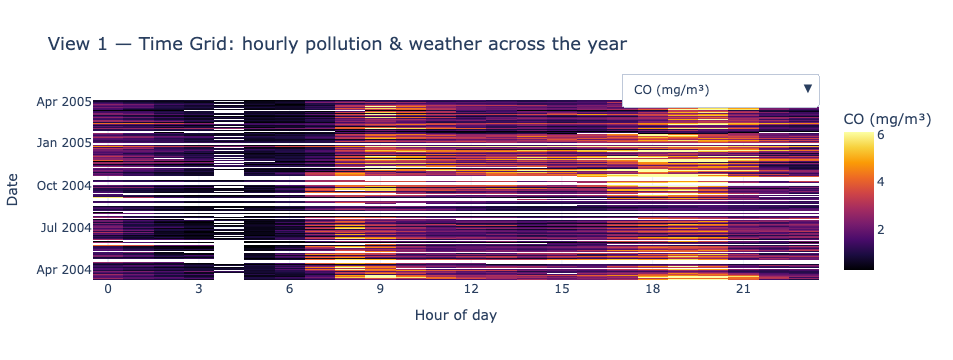

In [7]:
def view_time_grid(df):
    df = df.copy()
    df["Day"] = df["DateTime"].dt.normalize()
    df["Hr"] = df["DateTime"].dt.hour

    # Use a common day grid so every attribute traces the same 391 days and the
    # y-axis stays aligned when the dropdown switches between attributes.
    all_days = sorted(df["Day"].unique())

    traces = []
    for attr in NUMERIC_ATTRIBUTES:
        pivot = (
            df.pivot_table(index="Day", columns="Hr", values=attr, aggfunc="mean")
            .reindex(all_days)
        )
        traces.append(
            go.Heatmap(
                z=pivot.values,
                x=list(pivot.columns),
                y=pivot.index.to_pydatetime(),
                colorscale=colorscale_for(attr),
                zmin=df[attr].quantile(0.02),   # review fix: clamp colour at 2nd-98th percentile
                zmax=df[attr].quantile(0.98),   # so rare spikes do not darken the whole grid
                colorbar=dict(title=ATTR_LABELS[attr]),
                name=ATTR_LABELS[attr],
                hovertemplate=(
                    "Date: %{y|%Y-%m-%d}<br>Hour: %{x}:00<br>"
                    + ATTR_LABELS[attr]
                    + ": %{z:.2f}<extra></extra>"
                ),
                visible=(attr == "CO(GT)"),
            )
        )

    buttons = [
        dict(
            label=ATTR_LABELS[attr],
            method="update",
            args=[{"visible": [a == attr for a in NUMERIC_ATTRIBUTES]}],
        )
        for attr in NUMERIC_ATTRIBUTES
    ]

    fig = go.Figure(data=traces)
    fig.update_layout(
        template="plotly_white",
        title=dict(
            text="View 1 — Time Grid: hourly pollution & weather across the year",
            font=dict(size=18),
        ),
        updatemenus=[
            dict(
                buttons=buttons,
                direction="down",
                showactive=True,
                x=1.0,
                xanchor="right",
                y=1.15,
                yanchor="top",
            )
        ],
        height=760,
    )
    fig.update_xaxes(title_text="Hour of day", dtick=3)
    fig.update_yaxes(title_text="Date", tickformat="%b %Y")
    return fig

view_time_grid(df).show()

### View 1.2: Parallel coordinates
One line per complete hour across Hour of day plus all attributes, coloured by season. Lines are drawn in random order so no season hides the others. Drag along an axis to brush; the dropdown isolates one season. Fixed axis ranges keep subsets comparable.

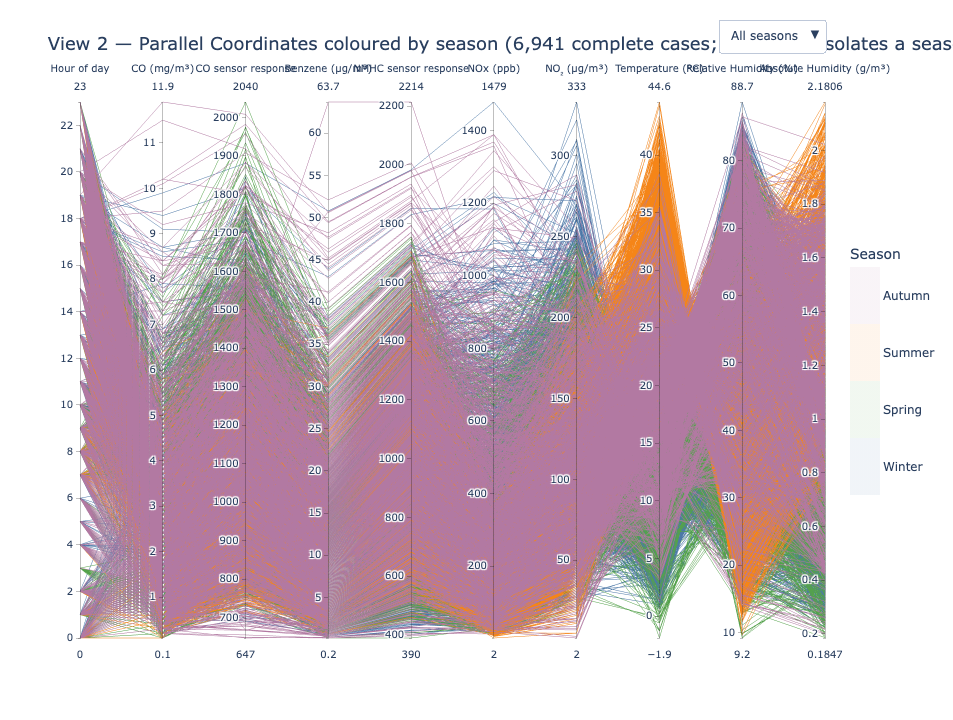

In [8]:
def view_parallel_coordinates(df):
    complete = df.dropna(subset=NUMERIC_ATTRIBUTES).sample(frac=1, random_state=0)   # review fix: shuffle draw order so no season paints over the others
    n_season = len(SEASON_ORDER) - 1

    # Fixed per-axis ranges from the full data, so a season subset still plots
    # on the same scale as "All seasons" and the bundles stay comparable.
    ranges = {c: [complete[c].min(), complete[c].max()] for c in NUMERIC_ATTRIBUTES}

    def dimensions(sub):
        hour_axis = [dict(label="Hour of day", values=sub["DateTime"].dt.hour.tolist(), range=[0, 23])]   # review fix: show which hours group together
        return hour_axis + [
            dict(label=ATTR_LABELS[c], values=sub[c].tolist(), range=ranges[c])
            for c in NUMERIC_ATTRIBUTES
        ]

    def make_trace(sub, alpha):
        return go.Parcoords(
            line=dict(
                color=sub["Season"].cat.codes.tolist(),
                colorscale=season_colorscale(alpha),
                cmin=-0.5,
                cmax=n_season + 0.5,
                showscale=True,
                colorbar=dict(
                    title="Season",
                    tickvals=list(range(len(SEASON_ORDER))),
                    ticktext=SEASON_ORDER,
                    len=0.5,
                ),
            ),
            dimensions=dimensions(sub),
        )

    # One trace per view; the dropdown toggles `visible` so exactly one is shown.
    # (Swapping `dimensions` via method="update" is unreliable for Parcoords,
    #  so each subset gets its own trace instead.)
    # review fix: lighter lines (alpha 0.08) in the "All seasons" overview
    subsets = [("All seasons", complete, 0.08)] + [
        (s, complete[complete["Season"] == s], 0.5) for s in SEASON_ORDER
    ]
    traces = [make_trace(sub, alpha) for _, sub, alpha in subsets]
    for i, tr in enumerate(traces):
        tr.visible = i == 0  # show "All seasons" by default

    fig = go.Figure(data=traces)
    buttons = [
        dict(
            label=label,
            method="update",
            args=[{"visible": [j == i for j in range(len(subsets))]}],
        )
        for i, (label, _, _) in enumerate(subsets)
    ]

    fig.update_layout(
        template="plotly_white",
        title=dict(
            text=f"View 2 — Parallel Coordinates coloured by season "
            f"({len(complete):,} complete cases; dropdown isolates a season)",
            font=dict(size=18),
        ),
        updatemenus=[
            dict(
                buttons=buttons,
                direction="down",
                showactive=True,
                x=1.0,
                xanchor="right",
                y=1.15,
                yanchor="top",
            )
        ],
        height=720,
    )
    return fig

view_parallel_coordinates(df).show()

### View 1.3: Scatterplot matrix
Every attribute pair, coloured by season, to spot dense regions and separations. Drawn from a 2,000-hour random sample of complete cases (the same sample size as the dashboard) so the notebook stays light.

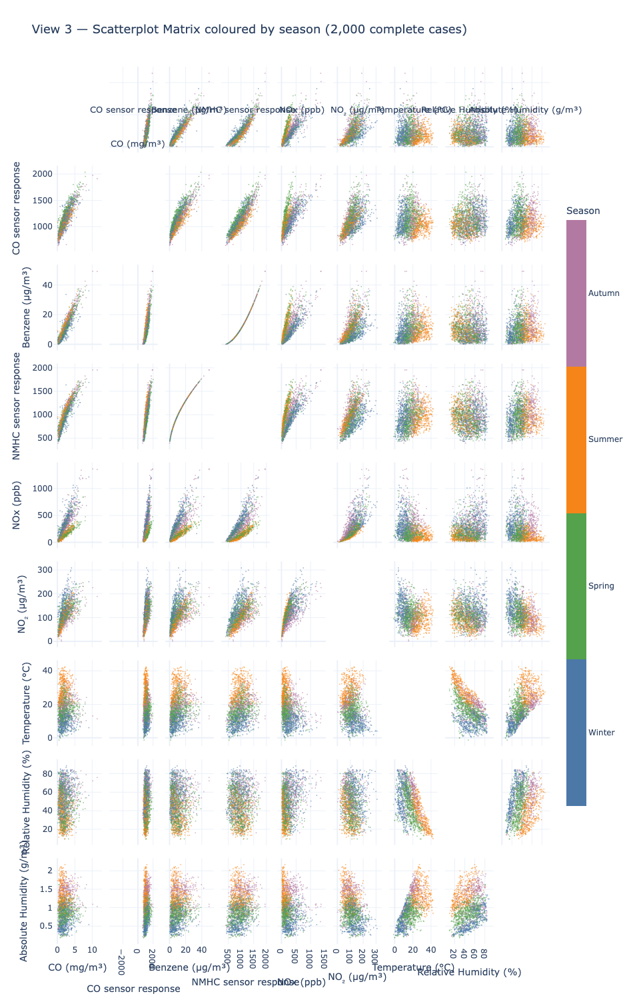

In [9]:
def view_splom(df):
    complete = df.dropna(subset=NUMERIC_ATTRIBUTES).copy()
    season_code = complete["Season"].cat.codes.tolist()
    colorscale = season_colorscale()
    n = len(NUMERIC_ATTRIBUTES)

    def axis_ref(letter: str, idx: int) -> str:
        # First axis is referenced as "x"/"y" (no number); subsequent as "x2", ...
        return letter if idx == 1 else f"{letter}{idx}"

    fig = make_subplots(
        rows=n,
        cols=n,
        shared_xaxes=True,
        shared_yaxes=True,
        horizontal_spacing=0.015,
        vertical_spacing=0.015,
    )

    for i, yattr in enumerate(NUMERIC_ATTRIBUTES):
        for j, xattr in enumerate(NUMERIC_ATTRIBUTES):
            if i == j:
                fig.add_annotation(
                    text=ATTR_LABELS[yattr],
                    x=0.5,
                    y=0.5,
                    xref=f"{axis_ref('x', j + 1)} domain",
                    yref=f"{axis_ref('y', i + 1)} domain",
                    showarrow=False,
                    font=dict(size=13),
                )
            else:
                fig.add_trace(
                    go.Scattergl(
                        x=complete[xattr],
                        y=complete[yattr],
                        mode="markers",
                        marker=dict(
                            color=season_code,
                            colorscale=colorscale,
                            cmin=-0.5,
                            cmax=len(SEASON_ORDER) - 0.5,
                            size=2,
                            opacity=0.55,
                            showscale=(i == 0 and j == 1),
                            colorbar=dict(
                                title="Season",
                                tickvals=list(range(len(SEASON_ORDER))),
                                ticktext=SEASON_ORDER,
                                len=0.7,
                            ),
                        ),
                        showlegend=False,
                    ),
                    row=i + 1,
                    col=j + 1,
                )

    for j, xattr in enumerate(NUMERIC_ATTRIBUTES):
        fig.update_xaxes(title_text=ATTR_LABELS[xattr], row=n, col=j + 1)
    for i, yattr in enumerate(NUMERIC_ATTRIBUTES):
        fig.update_yaxes(title_text=ATTR_LABELS[yattr], row=i + 1, col=1)

    fig.update_layout(
        template="plotly_white",
        title=dict(
            text=f"View 3 — Scatterplot Matrix coloured by season "
            f"({len(complete):,} complete cases)",
            font=dict(size=18),
        ),
        height=1500,
        width=1500,
    )
    return fig

view_splom(df.dropna(subset=ATTRS).sample(n=2000, random_state=42)).show()   # same 2,000-hour sample as app.py, keeps the notebook small

### View 1.4: Scatter (temperature vs pollutant)
Temperature against a pollutant chosen in the dropdown, coloured by season.

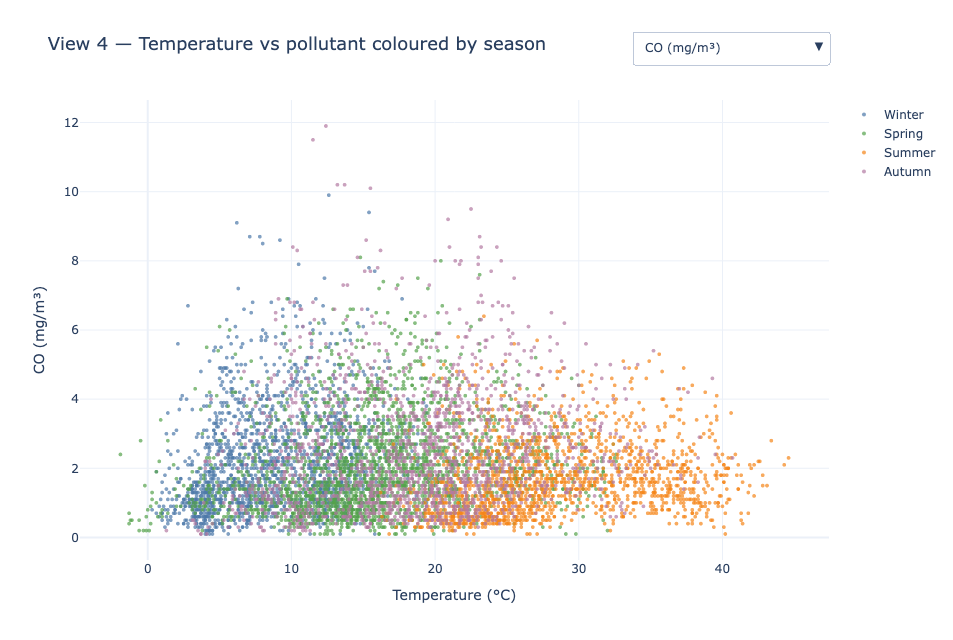

In [10]:
Y_OPTIONS = [
    "CO(GT)",
    "C6H6(GT)",
    "NOx(GT)",
    "NO2(GT)",
    "PT08.S1(CO)",
    "PT08.S2(NMHC)",
    "RH",
    "AH",
]

def view_scatter(df):
    df = df.copy()

    def season_xy(attr):
        xs, ys = [], []
        for s in SEASON_ORDER:
            sub = df[df["Season"] == s].dropna(subset=["T", attr])
            xs.append(sub["T"].tolist())
            ys.append(sub[attr].tolist())
        return xs, ys

    xs, ys = season_xy("CO(GT)")
    traces = [
        go.Scattergl(
            x=xs[i],
            y=ys[i],
            mode="markers",
            name=SEASON_ORDER[i],
            marker=dict(color=SEASON_COLORS[SEASON_ORDER[i]], size=4, opacity=0.7),
        )
        for i in range(len(SEASON_ORDER))
    ]

    buttons = []
    for attr in Y_OPTIONS:
        axs, ays = season_xy(attr)
        buttons.append(
            dict(
                label=ATTR_LABELS[attr],
                method="update",
                args=[
                    {"x": axs, "y": ays},
                    {"yaxis.title.text": ATTR_LABELS[attr]},
                    list(range(len(SEASON_ORDER))),
                ],
            )
        )

    fig = go.Figure(data=traces)
    fig.update_layout(
        template="plotly_white",
        title=dict(
            text="View 4 — Temperature vs pollutant coloured by season",
            font=dict(size=18),
        ),
        updatemenus=[
            dict(
                buttons=buttons,
                direction="down",
                showactive=True,
                x=1.0,
                xanchor="right",
                y=1.15,
                yanchor="top",
            )
        ],
        height=640,
    )
    fig.update_xaxes(title_text=ATTR_LABELS["T"])
    fig.update_yaxes(title_text=ATTR_LABELS["CO(GT)"])
    return fig

view_scatter(df).show()

### View 1.5: Weekday x hour heatmap
Mean value per weekday and hour (missing values skipped, not imputed), showing the weekly cycle.

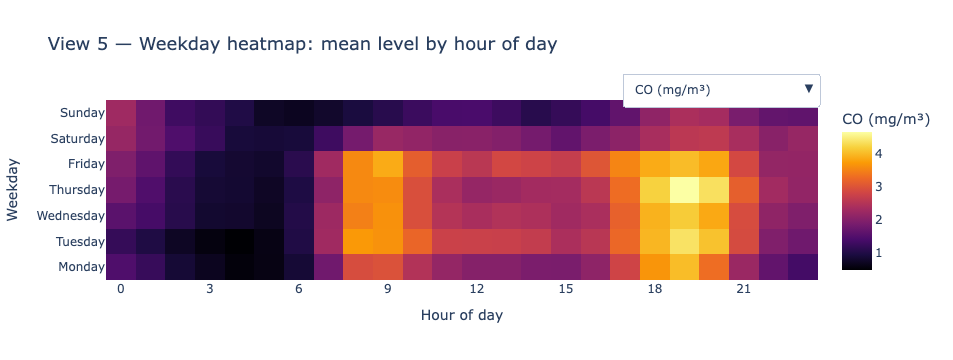

In [11]:
def view_weekday_heatmap(df):
    df = df.copy()
    df["WD"] = df["DateTime"].dt.day_name()
    df["Hr"] = df["DateTime"].dt.hour

    traces = []
    for attr in NUMERIC_ATTRIBUTES:
        agg = (
            df.pivot_table(index="WD", columns="Hr", values=attr, aggfunc="mean")
            .reindex(WEEKDAY_ORDER)
        )
        traces.append(
            go.Heatmap(
                z=agg.values,
                x=list(agg.columns),
                y=agg.index.tolist(),
                colorscale=colorscale_for(attr),
                colorbar=dict(title=ATTR_LABELS[attr]),
                name=ATTR_LABELS[attr],
                hovertemplate=(
                    "Weekday: %{y}<br>Hour: %{x}:00<br>"
                    + ATTR_LABELS[attr]
                    + ": %{z:.2f}<extra></extra>"
                ),
                visible=(attr == "CO(GT)"),
            )
        )

    buttons = [
        dict(
            label=ATTR_LABELS[attr],
            method="update",
            args=[{"visible": [a == attr for a in NUMERIC_ATTRIBUTES]}],
        )
        for attr in NUMERIC_ATTRIBUTES
    ]

    fig = go.Figure(data=traces)
    fig.update_layout(
        template="plotly_white",
        title=dict(
            text="View 5 — Weekday heatmap: mean level by hour of day",
            font=dict(size=18),
        ),
        updatemenus=[
            dict(
                buttons=buttons,
                direction="down",
                showactive=True,
                x=1.0,
                xanchor="right",
                y=1.15,
                yanchor="top",
            )
        ],
        height=520,
    )
    fig.update_xaxes(title_text="Hour of day", dtick=3)
    fig.update_yaxes(title_text="Weekday")
    return fig

view_weekday_heatmap(df).show()

### View 1.6: Linked-brushing dashboard (B's Dash app)
`app.py` links all five views: box/lasso in the scatter or SPLOM, or brushing a parallel-coordinates axis, highlights the same hours in every other view. It needs a running kernel, so it is off by default; set `RUN_DASH = True` to open it inside the notebook (or run `python app.py` and open http://127.0.0.1:8050). Screenshots of the linked selections are saved below as evidence.

In [12]:
RUN_DASH = False
if RUN_DASH:
    from app import app
    app.run(jupyter_mode="inline", port=8050)

### Task 1 evidence and findings (B)

**G1: Cooler high-NOx profile** (966 hours lasso-selected in T vs NOx)

![G1 linked evidence](docs/task1/figures/A_composite_cold_highNOx.png)

**G2: Elevated CO-NOx multi-pollutant profile** (1,710 hours lasso-selected in CO vs NOx)

![G2 linked evidence](docs/task1/figures/B_composite_pollution_cluster.png)

| Grouping | Members (hours / days) | Visual evidence (figure) | Defining attributes |
|---|---|---|---|
| G1 Cooler high-NOx | 966 hours, located mainly Nov 2004 to Mar 2005 in the time grid | Compact cool region above the NOx background (T vs NOx scatter); linked parallel coordinates; NOx time grid | Low T with elevated NOx |
| G2 Elevated CO-NOx | 1,710 hours, concentrated on weekday mornings 08-09 and evenings 18-20, fewer on weekends | Upper-right region of CO vs NOx scatter; linked parallel coordinates; weekday x hour count map | High CO, CO sensor, Benzene, NMHC sensor, NOx, NO2; T, RH, AH spread widely |
| G3 | TODO | TODO | TODO |
| G4 | TODO | TODO | TODO |

Full write-up: B's Task 1 report. Heuristic evaluation by B: `docs/task1/evaluation_report.md` (input for Task 4).

---
# 2. Task 2: Trend Analysis (10 pts)
**Owner: C (Nguyen Huu Hoang Duc)** · depends on the groupings locked by B

**Rubric checklist**
- [ ] Justify how each visualisation was produced with respect to the task
- [ ] Show visual evidence of **membership change** (time periods moving between groupings)
- [ ] Show visual evidence of **change in the attribute combination** defining a grouping
- [ ] Show **both changes in the same visualisation** (required by the rubric)

**Tasks**
1. Animated view through time (e.g. weekly scatter with Play)
2. Small multiples: diurnal profile per month for a chosen attribute
3. One view showing both changes together (e.g. monthly parallel coordinates of hourly medians with a month slider, or an hour x attribute fingerprint heatmap per month)
4. Pick the months / frames that best show each change and screenshot them
5. Write which periods moved between groupings, when, and which attributes took over

### Task 2 setup
Uses the same data (`df`) and the same attributes (`ATTRS`) as Task 1. Hour band is an encoding helper only: it colours lines and points so we can see which hours move between groups. No clustering is used.

In [13]:
BAND_ORDER = ["Night 00-05", "Morning rush 06-10", "Midday 11-16", "Evening rush 17-21", "Late 22-23"]
BAND_COLORS = dict(zip(BAND_ORDER, ["#4a6fa5", "#e0823d", "#d8b23a", "#c4455a", "#7b5ea7"]))
band_of = lambda h: BAND_ORDER[0 if h <= 5 else 1 if h <= 10 else 2 if h <= 16 else 3 if h <= 21 else 4]

t2 = df.copy()
t2["Hour"] = t2["DateTime"].dt.hour
t2["MonthLabel"] = t2["DateTime"].dt.to_period("M").astype(str)
t2["HourBand"] = t2["Hour"].map(band_of)
MONTHS = sorted(t2["MonthLabel"].unique())

def discrete_scale(colors):
    n = len(colors); out = []
    for i, c in enumerate(colors):
        out += [[i / n, c], [(i + 1) / n, c]]
    return out
print(len(MONTHS), "months:", MONTHS[0], "to", MONTHS[-1])

14 months: 2004-03 to 2005-04


### View 2.1: Animated time-window view
Benzene vs NOx, one frame per week, coloured by hour band. Axes are fixed, so any movement between frames is real change. Press **Play** and watch where each colour sits as the year passes.

**What to look for:** in spring and summer the rush-hour points (orange/red) stretch along a shallow line (lots of benzene, moderate NOx). In August they collapse into the low corner (holiday traffic). From September, and strongly from November, the same rush-hour points climb onto a much steeper line (far more NOx for the same benzene).

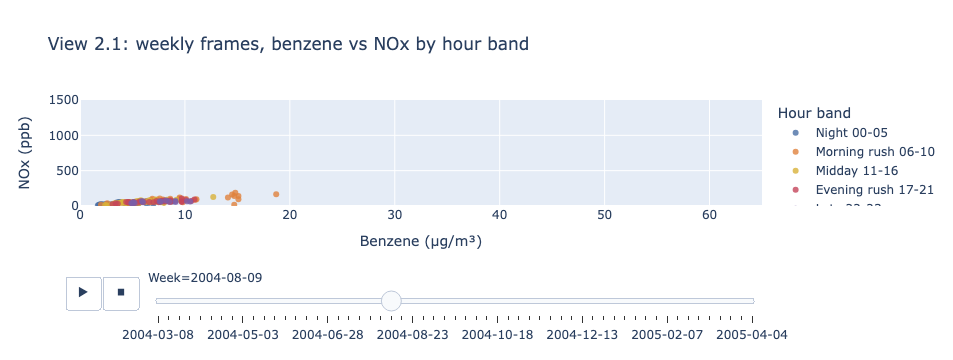

In [14]:
an = t2.dropna(subset=["C6H6(GT)", "NOx(GT)"]).sort_values("DateTime").copy()
an["Week"] = an["DateTime"].dt.to_period("W-SUN").dt.start_time.dt.strftime("%Y-%m-%d")
fig = px.scatter(an, x="C6H6(GT)", y="NOx(GT)", color="HourBand", animation_frame="Week",
                 color_discrete_map=BAND_COLORS, category_orders={"HourBand": BAND_ORDER},
                 range_x=[0, 65], range_y=[0, 1500], opacity=0.8, height=560,
                 hover_data={"DateTime": True, "T": True, "RH": True},
                 labels={"C6H6(GT)": ATTR_LABELS["C6H6(GT)"], "NOx(GT)": ATTR_LABELS["NOx(GT)"], "HourBand": "Hour band"},
                 title="View 2.1: weekly frames, benzene vs NOx by hour band")
fig.layout.updatemenus[0].buttons[0].args[1]["frame"]["duration"] = 350
fig.show()

### View 2.2: Monthly diurnal small multiples
One panel per month: median by hour of day (green) against the full-year median (grey). Shaded columns mark 06-10 and 17-21. Use the dropdown to change attribute. Small multiples let all months be compared side by side, which complements the animation (animation alone relies on memory between frames).

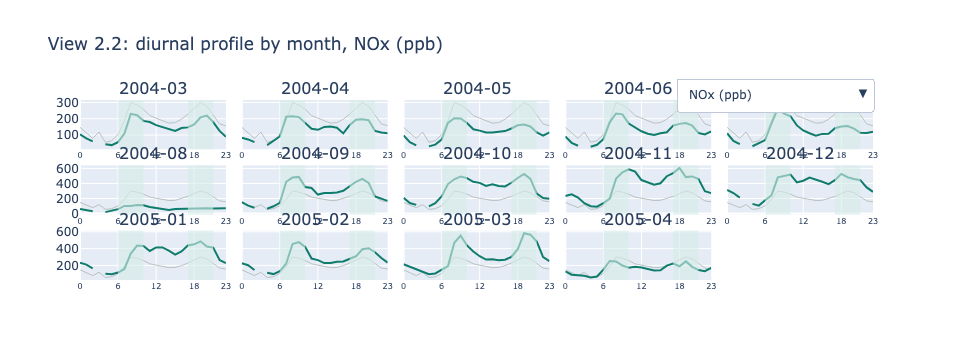

In [15]:
ncol = 5; nrow = int(np.ceil(len(MONTHS) / ncol))
fig = make_subplots(rows=nrow, cols=ncol, subplot_titles=MONTHS, shared_yaxes=True,
                    horizontal_spacing=0.02, vertical_spacing=0.09)
for a in ATTRS:
    year = t2.groupby("Hour")[a].median()
    prof = t2.groupby(["MonthLabel", "Hour"])[a].median().unstack()
    for j, m in enumerate(MONTHS):
        r, c = j // ncol + 1, j % ncol + 1
        fig.add_trace(go.Scatter(x=year.index, y=year.values, line=dict(color="#b8c2bf", width=1),
                                 visible=(a == "NOx(GT)"), showlegend=False, hoverinfo="skip"), r, c)
        fig.add_trace(go.Scatter(x=prof.columns, y=prof.loc[m].values, line=dict(color="#0f7c6c", width=2),
                                 visible=(a == "NOx(GT)"), showlegend=False,
                                 hovertemplate=f"{m} %{{x}}:00 · {a} %{{y}}<extra></extra>"), r, c)
per_attr = 2 * len(MONTHS)
buttons = [dict(label=ATTR_LABELS[a], method="update",
                args=[{"visible": [k // per_attr == i for k in range(len(fig.data))]},
                      {"title.text": f"View 2.2: diurnal profile by month, {ATTR_LABELS[a]}"}])
           for i, a in enumerate(ATTRS)]
for j in range(len(MONTHS)):
    for x0, x1 in [(6, 10), (17, 21)]:
        fig.add_vrect(x0=x0, x1=x1, fillcolor="#d6ece7", opacity=0.6, line_width=0, row=j // ncol + 1, col=j % ncol + 1)
fig.update_xaxes(tickvals=[0, 6, 12, 18, 23], tickfont=dict(size=8))
fig.update_layout(height=620, title=f"View 2.2: diurnal profile by month, {ATTR_LABELS['NOx(GT)']}",
                  updatemenus=[dict(buttons=buttons, active=ATTRS.index("NOx(GT)"), x=1.0, xanchor="right", y=1.12)])
fig.show()

### View 2.3: Membership + attribute change in one view (main evidence)
**Monthly parallel coordinates.** Each frame is one month. Each of the 24 lines is one hour of the day at its monthly median, coloured by hour band. Axis ranges are fixed across months. One view shows both changes the rubric asks for:
- **Membership change:** which coloured lines bundle together (e.g. do the yellow midday lines sit with the low night bundle or with the high rush-hour bundle?).
- **Defining-attribute change:** on which axes the high bundle sits (benzene/CO/NMHC high in summer; NOx/NO2 high with low T and AH in winter).

Press **Play** or drag the month slider.

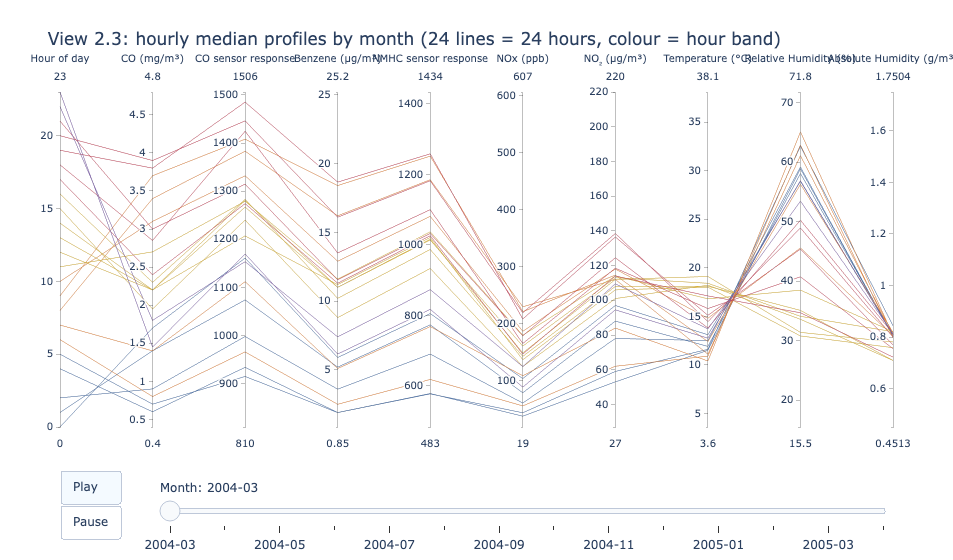

Colour key: {'Night 00-05': '#4a6fa5', 'Morning rush 06-10': '#e0823d', 'Midday 11-16': '#d8b23a', 'Evening rush 17-21': '#c4455a', 'Late 22-23': '#7b5ea7'}


In [16]:
prof_all = t2.groupby(["MonthLabel", "Hour"])[ATTRS].median()
rng = {a: [float(prof_all[a].min()), float(prof_all[a].max())] for a in ATTRS}
hour_codes = [BAND_ORDER.index(band_of(h)) for h in range(24)]

def month_pc(m):
    p = prof_all.loc[m].reindex(range(24))
    dims = [dict(label="Hour of day", values=list(range(24)), range=[0, 23])] + \
           [dict(label=ATTR_LABELS[a], values=p[a].values, range=rng[a]) for a in ATTRS]
    return go.Parcoords(dimensions=dims,
                        line=dict(color=hour_codes, colorscale=discrete_scale(list(BAND_COLORS.values())),
                                  cmin=-0.5, cmax=len(BAND_ORDER) - 0.5))

fig = go.Figure(data=[month_pc(MONTHS[0])], frames=[go.Frame(data=[month_pc(m)], name=m) for m in MONTHS])
fig.update_layout(
    title="View 2.3: hourly median profiles by month (24 lines = 24 hours, colour = hour band)",
    height=560, margin=dict(l=60, r=60, t=90, b=90),
    updatemenus=[dict(type="buttons", x=0, y=-0.12, xanchor="left", buttons=[
        dict(label="Play", method="animate", args=[None, {"frame": {"duration": 900, "redraw": True}, "fromcurrent": True}]),
        dict(label="Pause", method="animate", args=[[None], {"frame": {"duration": 0, "redraw": False}, "mode": "immediate"}])])],
    sliders=[dict(x=0.12, y=-0.08, len=0.88, currentvalue=dict(prefix="Month: "),
                  steps=[dict(label=m, method="animate",
                              args=[[m], {"frame": {"duration": 0, "redraw": True}, "mode": "immediate"}]) for m in MONTHS])])
fig.show()
print("Colour key:", BAND_COLORS)

### View 2.4: Hour x attribute fingerprint by month (same two changes, second encoding)
Rows = hours, columns = attributes. Colour = how far that hour's monthly median sits above (red) or below (blue) the attribute's full-year median, in IQR units (robust to outliers and comparable across units). A **row turning red** = that hour joined the polluted group (membership). A **column turning red** = that attribute joined the defining combination. White cells at 03:00 for NOx/NO2 are the known missing-data gap.

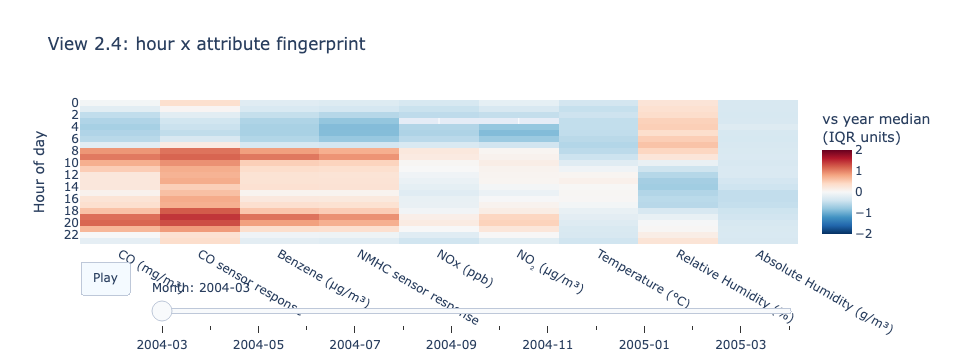

In [17]:
med_all = t2[ATTRS].median()
iqr_all = t2[ATTRS].quantile(0.75) - t2[ATTRS].quantile(0.25)
xlabels = [ATTR_LABELS[a] for a in ATTRS]
def fingerprint(m):
    return ((prof_all.loc[m].reindex(range(24)) - med_all) / iqr_all).clip(-2, 2)
def hm(m):
    return go.Heatmap(z=fingerprint(m).values, x=xlabels, y=list(range(24)), zmin=-2, zmax=2,
                      colorscale="RdBu_r", colorbar=dict(title="vs year median<br>(IQR units)"))
fig = go.Figure(data=[hm(MONTHS[0])], frames=[go.Frame(data=[hm(m)], name=m) for m in MONTHS])
fig.update_layout(title="View 2.4: hour x attribute fingerprint", height=640,
    yaxis=dict(autorange="reversed", title="Hour of day", dtick=2),
    updatemenus=[dict(type="buttons", x=0, y=-0.12, xanchor="left", buttons=[
        dict(label="Play", method="animate", args=[None, {"frame": {"duration": 900, "redraw": True}, "fromcurrent": True}])])],
    sliders=[dict(x=0.1, y=-0.08, len=0.9, currentvalue=dict(prefix="Month: "),
                  steps=[dict(label=m, method="animate",
                              args=[[m], {"frame": {"duration": 0, "redraw": True}, "mode": "immediate"}]) for m in MONTHS])])
fig.show()

In [18]:
# Numbers quoted in the findings, read off View 2.4 (IQR units) and View 2.2 (NOx medians)
for m in ["2004-07", "2004-08", "2004-11", "2005-02"]:
    print(m); display(fingerprint(m).loc[[8, 13, 19, 23]].round(1))
display(prof_all["NOx(GT)"].unstack().loc[:, [0, 8, 13, 19]].round(0))

2004-07


,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),NO2(GT),T,RH,AH
Hour,,,,,,,,,
8,0.9,0.7,1.8,1.4,0.4,0.2,0.5,-0.2,0.5
13,0.1,-0.2,0.2,0.2,-0.3,0.0,1.6,-1.2,0.2
19,0.8,0.1,0.9,0.7,-0.1,0.4,1.2,-1.0,0.1
23,0.1,0.1,0.3,0.3,-0.3,-0.1,0.7,-0.4,0.5


2004-08


,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),NO2(GT),T,RH,AH
Hour,,,,,,,,,
8,-0.1,0.1,0.5,0.4,-0.3,-0.7,0.6,0.2,1.3
13,-0.4,-0.5,-0.3,-0.3,-0.6,-0.7,1.4,-0.8,1.0
19,-0.1,-0.1,0.0,0.0,-0.5,-0.4,1.0,-0.5,1.2
23,-0.2,-0.1,-0.1,-0.1,-0.5,-0.6,0.7,0.1,1.3


2004-11


,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),NO2(GT),T,RH,AH
Hour,,,,,,,,,
8,0.4,0.6,0.8,0.7,1.2,0.2,-0.6,0.8,-0.1
13,0.4,0.4,0.4,0.3,1.0,0.5,-0.2,-0.0,0.0
19,1.4,0.8,1.3,1.0,1.3,0.8,-0.3,0.3,0.0
23,0.0,-0.0,-0.1,-0.1,0.4,-0.1,-0.5,0.7,-0.1


2005-02


,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),NO2(GT),T,RH,AH
Hour,,,,,,,,,
8,0.3,0.5,0.3,0.3,1.2,1.5,-1.1,0.5,-0.9
13,-0.1,-0.1,-0.2,-0.2,0.2,0.5,-0.6,-0.5,-0.9
19,0.8,0.4,0.4,0.4,0.9,1.5,-0.8,-0.3,-0.9
23,-0.1,-0.0,-0.3,-0.3,0.2,0.8,-0.9,-0.0,-0.9


Hour,0,8,13,19
MonthLabel,,,,
2004-03,104.0,230.0,149.0,208.0
2004-04,83.0,215.0,150.0,197.0
2004-05,98.0,203.0,115.0,164.0
2004-06,91.0,232.0,108.0,173.0
2004-07,111.0,262.0,111.0,155.0
2004-08,62.0,101.0,54.0,70.0
2004-09,152.0,478.0,273.0,460.0
2004-10,209.0,455.0,368.0,526.0
2004-11,234.0,464.0,416.0,484.0


### Task 2 findings (C)

**Membership changes**

| Change | When | Visual evidence |
|---|---|---|
| Midday hours (11-16) join the high-pollution group | From Sep-Oct 2004, strongest Oct 2004 to Jan 2005 | View 2.4: 13:00 row turns red (NOx -0.3 in Jul → +1.0 in Nov). View 2.3: yellow lines leave the low bundle and join the rush-hour lines. View 2.2: midday NOx plateau ~110 in Jun-Jul vs ~370-480 in Oct-Jan |
| Late hours (22-00) join the polluted group | Winter (Nov 2004 to Mar 2005) | View 2.2: NOx at 00:00 ~90-110 in Mar-Jul vs ~210-315 in Oct-Mar. View 2.4: 23:00 row turns pink in Nov (NOx +0.4) and Feb (NO2 +0.8) |
| Rush hours leave the traffic group, then return | Mid-August 2004 → early September | View 2.1: weekday rush points collapse into the low corner for the August weeks and return in September. View 2.4: 08:00 row fades from strong red in Jul (benzene +1.8) to near neutral in Aug (+0.5, NO2 -0.7). NOx at 08:00 drops 262 → 101 |

**Defining-attribute changes** (08:00 rush-hour group, View 2.4)

| Month | Defining combination |
|---|---|
| Jul 2004 | Benzene +1.8, NMHC sensor +1.4, CO +0.9; NOx only +0.4; warm (T +0.5), dry |
| Nov 2004 | NOx leads (+1.2); benzene down to +0.8; humid (RH +0.8), cooler (T -0.6) |
| Feb 2005 | NO2 +1.5 and NOx +1.2 lead; benzene only +0.3; cold and dry air (T -1.1, AH -0.9) |

**Summary:** the traffic group changes from **benzene/CO/NMHC + warm + dry** in the warm season to **NOx/NO2 + cold + humid (low AH)** in the cold season. View 2.1 shows the same switch as rush-hour points moving from a shallow benzene-NOx line onto a steep one. These changes feed Task 3, which looks for the critical moment when the switch happens.

### Literature survey (C)
| Reference | Supports |
|---|---|
| Inselberg, A. (1985). The plane with parallel coordinates. *The Visual Computer*, 1(2), 69-91. | Parallel coordinates for multivariate groups (View 1.2, View 2.3) |
| Heinrich, J., & Weiskopf, D. (2013). State of the art of parallel coordinates. *Eurographics 2013 STAR*, 95-116. | Overplotting, axis ordering, brushing in parallel coordinates |
| Becker, R. A., & Cleveland, W. S. (1987). Brushing scatterplots. *Technometrics*, 29(2), 127-142. | Brushing and linking (Task 1 dashboard) |
| Tufte, E. R. (1990). *Envisioning Information*. Graphics Press. | Small multiples (View 2.2) |
| Robertson, G., Fernandez, R., Fisher, D., Lee, B., & Stasko, J. (2008). Effectiveness of animation in trend visualization. *IEEE TVCG*, 14(6), 1325-1332. | Animation vs small multiples for trends (View 2.1 + 2.2 used together) |
| Van Wijk, J. J., & Van Selow, E. R. (1999). Cluster and calendar based visualization of time series data. *Proc. IEEE InfoVis '99*, 4-9. | Calendar / day x hour views (View 1.1, View 2.4) |
| Aigner, W., Miksch, S., Schumann, H., & Tominski, C. (2011). *Visualization of Time-Oriented Data*. Springer. | Design of temporal views |
| Munzner, T. (2014). *Visualization Analysis and Design*. CRC Press. | Marks and channels, colour choices, nested evaluation model (Task 4) |
| De Vito, S., Massera, E., Piga, M., Martinotto, L., & Di Francia, G. (2008). On field calibration of an electronic nose for benzene estimation in an urban pollution monitoring scenario. *Sensors and Actuators B: Chemical*, 129(2), 750-757. | Source of the UCI Air Quality dataset |

---
# 3. Task 3: Prediction / Critical Moment (10 pts)
**Owner: A (Wang Yuyao)** · depends on the changes found by C

**Rubric checklist**
- [ ] Justify how each visualisation was produced with respect to the task
- [ ] Identify a critical moment that is clearly visible in a visualisation (membership or attribute-combination change)
- [ ] Identify alternative changes in environmental attributes (T, RH, AH) that would have prevented it, and explain how the visualisation shows this
- [ ] Use visual evidence (what-if modelling, regression projection or animation) to justify the prediction

**Tasks**
1. Daily view of a group indicator (e.g. NOx per unit benzene) with T and AH on a shared time axis, with range slider
2. Choose the critical moment and before / after windows; compare them visually
3. Fit a simple regression linking pollutants to T, AH, RH (state R² and limitations)
4. What-if bench with sliders (ΔT, ΔAH, ΔRH) showing projected points against the before group
5. What-if inside the grouping view (parallel coordinates: before / after / projected)
6. Map of alternative changes (ΔT x ΔAH) showing which combinations keep the group

### View 3.1: Critical moment view

In [19]:
# TODO (A)


### View 3.2: Regression model

In [20]:
# TODO (A)


### View 3.3: What-if bench (sliders)

In [21]:
# TODO (A)


### View 3.4: What-if parallel coordinates

In [22]:
# TODO (A)


### View 3.5: Alternative-changes map

In [23]:
# TODO (A)


### Task 3 findings (A)
| Item | Value / evidence |
|---|---|
| Critical moment | TODO |
| Before vs after (T, AH, group indicator) | TODO |
| Scenarios tested and result | TODO |
| Alternative changes that keep the group | TODO |
| Limitations | TODO |

---
# 4. Task 4: Evaluation of Visualisation (10 pts)
**Owner: D (Tang Yaqing)** · all members run at least 1 session

**Rubric checklist**
- [ ] Explain and justify the evaluation methods and procedure, designed for this specific tool
- [ ] Present evidence of improvement resulting from the evaluation (before vs after)

**Tasks**
1. Design the protocol: heuristic walkthrough + task-based think-aloud (insight-based evaluation)
2. Write 3 participant tasks mapped to Tasks 1-3; define measures (time to first correct insight, number of insights, errors)
3. Recruit 4-5 participants (classmates outside the group); each member runs at least 1 session
4. Analyse results and list problems found per view
5. Assign fixes to view owners; produce v1 vs v2 before/after figures below
6. Write how each change improved the discovery of visual evidence

### Evaluation protocol

TODO (D): participants, tasks, measures, procedure, why these methods fit this tool

### Results

| Participant | Task | Time to insight | Insights | Errors / confusion | Run by |
|---|---|---|---|---|---|
| P1 | TODO | TODO | TODO | TODO | TODO |

### Before vs after figures

In [24]:
# TODO (D + view owners): v1 vs v2 figures for each design change


### Design changes
| Finding | Change made | View / owner | Improvement shown |
|---|---|---|---|
| TODO | TODO | TODO | TODO |

---
# 5. Report assembly checklist (D)
- [ ] Group report max 8 pages; sections: Data, Task 1, Task 2, Task 3, Task 4, design justification
- [ ] Every claim references a figure; figures numbered from the registry
- [ ] Same attributes used in every task; no clustering algorithm mentioned or used
- [ ] References from C cited consistently
- [ ] Peer review done (A-D, B-C)
- [ ] Notebook runs top to bottom without errors (A)
- [ ] Individual reports (max 4 pages each): non-visualisation contribution (5 pts) + visualisation contribution (15 pts), tied to each member's row in the role table